In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from ipynb.fs.full.preprocessing import process_the_data, read_the_data

<h3> Looking at the steps calculated by DeltabotController

In [5]:
mesh0045_27Oct = pd.read_csv("processed_data/27Oct_0045_mesh.csv")

We can see that the snaking behaviour of the steps

In [6]:
# algorithm_steps
print("Calculated Motor Values Max/Min")
print(max(mesh0045_27Oct["s0"]))
print(max(mesh0045_27Oct["s1"]))
print(max(mesh0045_27Oct["s2"]))
print(min(mesh0045_27Oct["s0"]))
print(min(mesh0045_27Oct["s1"]))
print(min(mesh0045_27Oct["s2"]))

Calculated Motor Values Max/Min
6144.0
8393.0
8393.0
-6144.0
-8393.0
-8393.0


<h1> LR Predictions

In [15]:
#gave those x and y values to the 16Oct MLP 
#output
pred_snake_steps = pd.read_csv("predictions/all_data_LR_Pred_snake_mesh.csv", names=["s0", "s1", "s2"], dtype="float32")
display(pred_snake_steps.head())
print("Predicted motor values Max/Min")
print(max(pred_snake_steps["s0"]))
print(max(pred_snake_steps["s1"]))
print(max(pred_snake_steps["s2"]))
print(min(pred_snake_steps["s0"]))
print(min(pred_snake_steps["s1"]))
print(min(pred_snake_steps["s2"]))

,s0,s1,s2
0,4575.481934,-5874.337891,1298.854492
1,4545.950684,-5566.870605,1020.918030
2,4516.419434,-5259.402832,742.981567
3,4486.888184,-4951.935059,465.045074
4,4457.356934,-4644.467285,187.108597


Predicted motor values Max/Min
4575.48193359375
6173.51611328125
4957.86669921875
-4460.9052734375
-5874.337890625
-5371.62109375


In [ ]:
pred_snake_steps['sum_motors'] = pred_snake_steps["s0"] + pred_snake_steps["s1"] + pred_snake_steps["s2"]
# display(pred_snake_steps['sum_motors'])
print("highest motor sum (no adjustments): ", max(pred_snake_steps["sum_motors"]))
print("lowest motor sum (no adjustments): ", min(pred_snake_steps["sum_motors"]))


pred_snake_steps["s0_adj"] = pred_snake_steps["s0"] - (pred_snake_steps["sum_motors"]/3)
pred_snake_steps["s1_adj"] = pred_snake_steps["s1"] - (pred_snake_steps["sum_motors"]/3)
pred_snake_steps["s2_adj"] = pred_snake_steps["s2"] - (pred_snake_steps["sum_motors"]/3)

pred_snake_steps['sum_motors_adj'] = pred_snake_steps["s0_adj"] + pred_snake_steps["s1_adj"] + pred_snake_steps["s2_adj"]
# display(pred_snake_steps['sum_motors'])
print(max(pred_snake_steps["sum_motors_adj"]))
print(min(pred_snake_steps["sum_motors_adj"]))
print(max(pred_snake_steps["s0_adj"]))
print(max(pred_snake_steps["s1_adj"]))
print(max(pred_snake_steps["s2_adj"]))
print(min(pred_snake_steps["s0_adj"]))
print(min(pred_snake_steps["s1_adj"]))
print(min(pred_snake_steps["s2_adj"]))


highest motor sum:  0.0017242929532130802
lowest motor sum:  -0.0015828003145088587
9.094947017729282e-13
-9.094947017729282e-13
4575.482529115935
6173.515385225978
4957.8664622967835
-4460.90608813708
-5874.337586025629
-5371.620702475989


Quite high strain if 278 / 260 sum of the motors

Text(0.5, 0.98, 'Predictions from Standard Scaled Linear Regression on all data - Snake Scan')

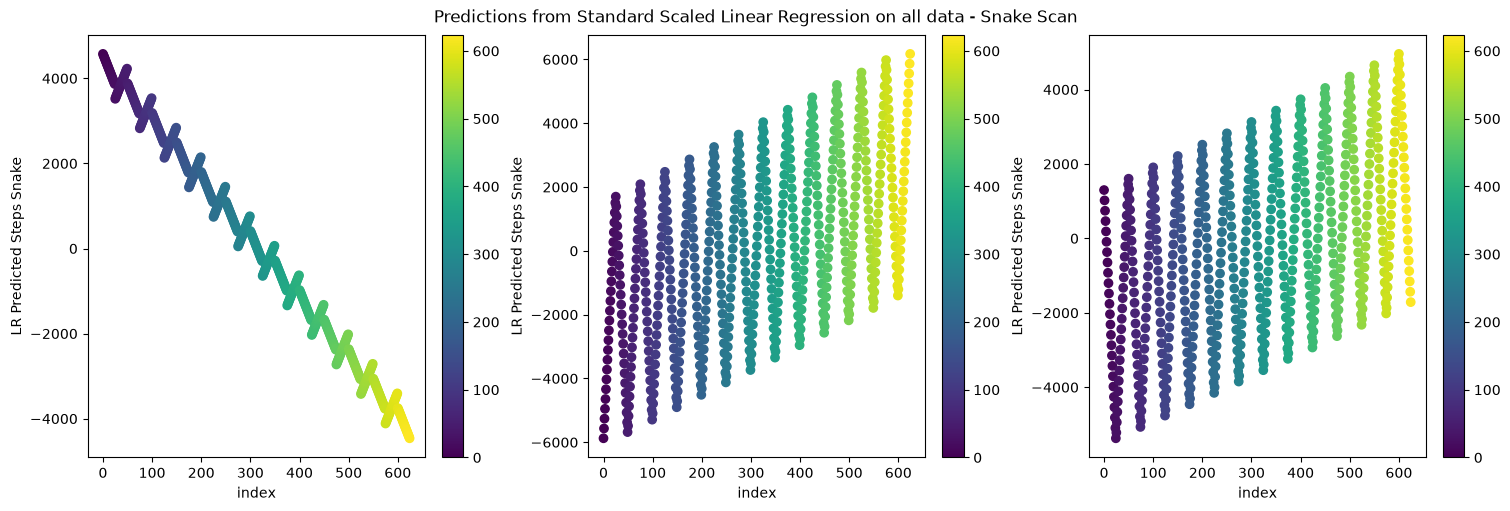

In [17]:
fig, axs = plt.subplots(1, 3, figsize=(15,5), constrained_layout=True)
for i, motor in enumerate(["s0", "s1", "s2"]):
    im = axs[i].scatter(pred_snake_steps[motor].index, pred_snake_steps[motor], c=pred_snake_steps.index)
    axs[i].set_xlabel("index")
    axs[i].set_ylabel("LR Predicted Steps Snake")
    fig.colorbar(im, ax=axs[i])  
fig.suptitle("Predictions from Standard Scaled Linear Regression on all data - Snake Scan")

Text(0.5, 0.98, 'Predictions from Standard Scaled MLP Snake Scan - motor values adjusted to sum to 0')

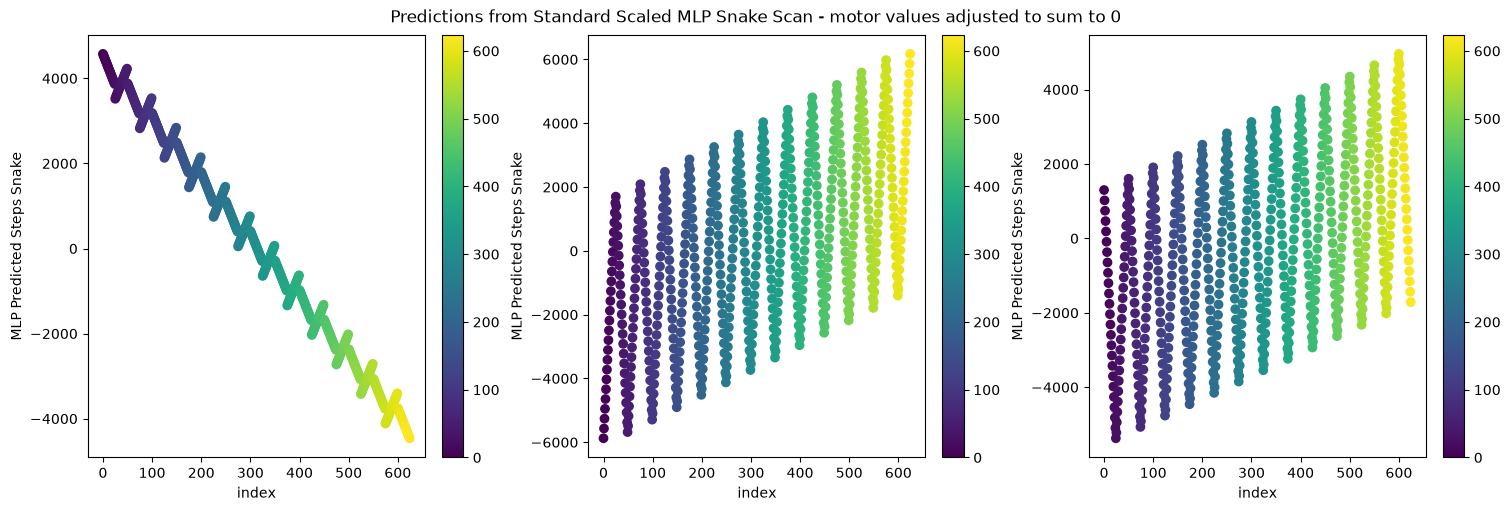

In [12]:
fig, axs = plt.subplots(1, 3, figsize=(15,5), constrained_layout=True)
for i, motor in enumerate(["s0_adj", "s1_adj", "s2_adj"]):
    im = axs[i].scatter(pred_snake_steps[motor].index, pred_snake_steps[motor], c=pred_snake_steps.index)
    axs[i].set_xlabel("index")
    axs[i].set_ylabel("MLP Predicted Steps Snake")
    fig.colorbar(im, ax=axs[i])
fig.suptitle("Predictions from Standard Scaled MLP Snake Scan - motor values adjusted to sum to 0")

<h2> Comparing the 2 datasets

Text(0.5, 0.98, 'DeltabotController Motor values vs Standard Scaled Linear Regression (all data) Predictions for snake scan')

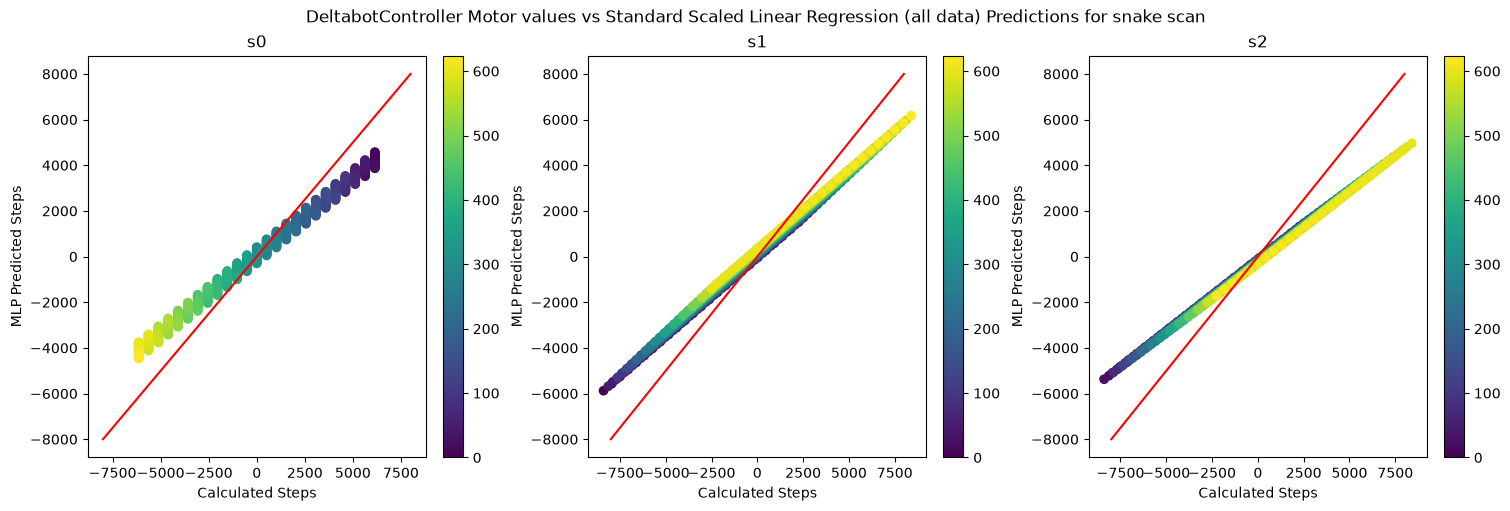

In [18]:
fig, axs = plt.subplots(1, 3, figsize=(15,5), constrained_layout=True)
for i, motor in enumerate(["s0", "s1", "s2"]):
    im = axs[i].scatter(mesh0045_27Oct[motor], pred_snake_steps[motor], c=mesh0045_27Oct["point"])
    axs[i].set_xlabel("Calculated Steps")
    axs[i].set_ylabel("MLP Predicted Steps")
    fig.colorbar(im, ax=axs[i])  
    axs[i].set_title(motor)
    lims = [-8000, 8000]
    # axs[i].set_xlim(lims)
    # axs[i].set_ylim(lims)
    _ = axs[i].plot(lims, lims, color="red")

fig.suptitle("DeltabotController Motor values vs Standard Scaled Linear Regression (all data) Predictions for snake scan")

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(15,5), constrained_layout=True)
for i, motor in enumerate(["s0", "s1", "s2"]):
    im = axs[i].scatter(mesh0045_27Oct[motor], pred_snake_steps[f"{motor}_adj"], c=mesh0045_27Oct["point"])
    axs[i].set_xlabel("Calculated Steps")
    axs[i].set_ylabel("MLP Predicted Steps")
    fig.colorbar(im, ax=axs[i])  
    axs[i].set_title(motor)
    lims = [-8000, 8000]
    # axs[i].set_xlim(lims)
    # axs[i].set_ylim(lims)
    _ = axs[i].plot(lims, lims, color="red")

fig.suptitle("DeltabotController Motor values vs Standard Scaled MLP Predictions for snake scan - values adjusted to sum to 0")

In [32]:
pred_snake_steps[["s0_adj", "s1_adj", "s2_adj"]].astype("int32").to_csv("predictions/adjusted/16Oct_MLP_Scaled_snake.csv", index=False)

In [ ]:
data = pd.read_csv("predictions/adjusted/16Oct_MLP_Scaled_snake.csv")
points = list(data.itertuples(index=False, name=None))
print(points)

In [38]:
# list(pred_snake_steps.itertuples(index=False, name=None))

<h1>Output from Scan using predicted LR motor values

In [19]:
path = "scripts/scans/MLP"
scan = "0015_LR_all"

x_conversion = 0.1/11
y_conversion = x_conversion

start_cx = 318#px
start_cy = 260 #px

scan_MLP = process_the_data(scan, path, x_conversion, y_conversion, start_cx, start_cy)
scan_MLP.name = "scan_LR"

In [ ]:
# scan_MLP

Text(0.5, 1.0, 'all data LR predictions scan')

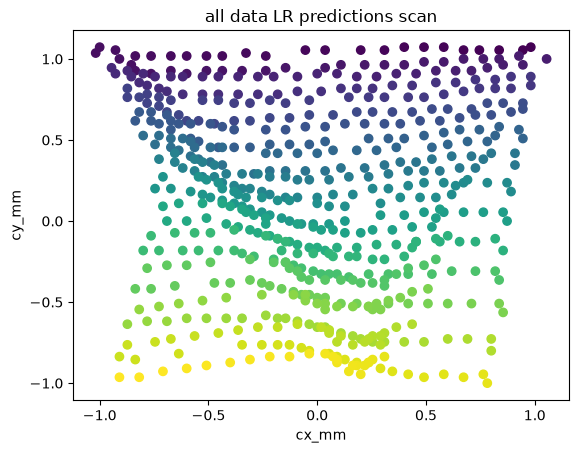

In [25]:
plt.scatter(scan_MLP["cx_mm"], scan_MLP["cy_mm"], c=scan_MLP["point"])
plt.xlabel("cx_mm")
plt.ylabel("cy_mm")
plt.title(f"all data LR predictions scan")

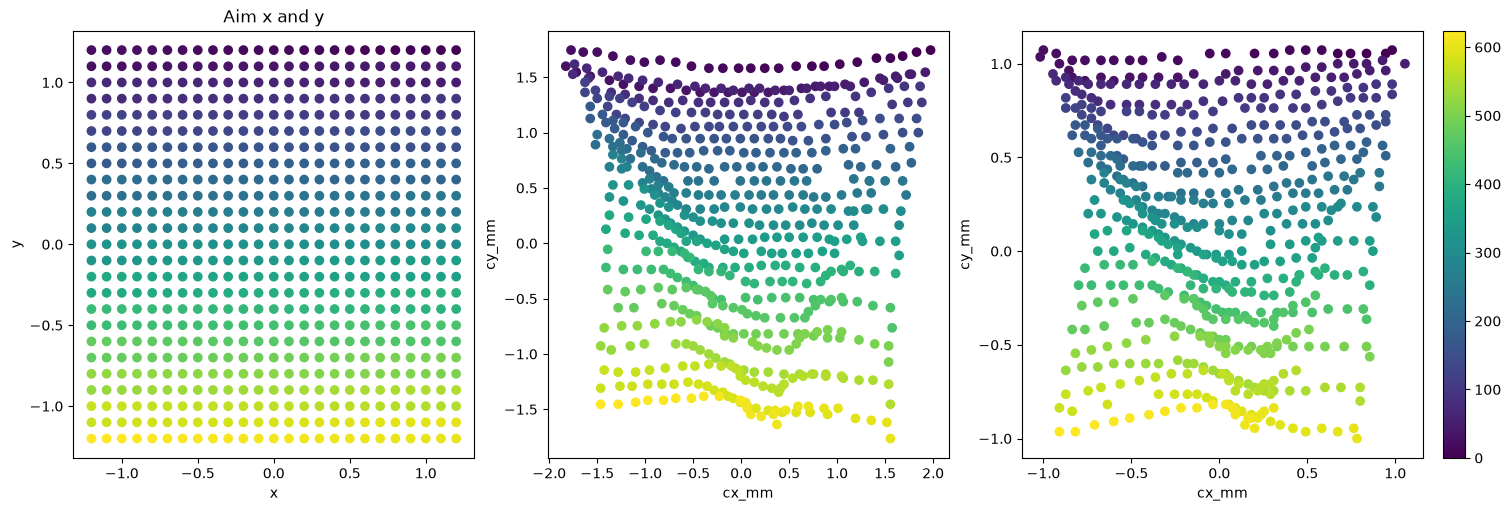

In [21]:
fig, axs = plt.subplots(1, 3, figsize=(15,5), constrained_layout=True)

im = axs[0].scatter(mesh0045_27Oct["x"], mesh0045_27Oct["y"], c=mesh0045_27Oct["point"])
axs[0].set_xlabel("x")
axs[0].set_ylabel("y")
axs[0].set_title("Aim x and y")

i = 1
for scan in mesh0045_27Oct, scan_MLP:
    suplot = axs[i]
    suplot.scatter(scan["cx_mm"], scan["cy_mm"], c=scan["point"])
    suplot.set_xlabel("cx_mm")
    suplot.set_ylabel("cy_mm")
    # fig.colorbar(im, ax=axs[i])  
    # suplot.set_title(scan.name)
    i = i+1

fig.colorbar(im, ax=axs[2])  